# Mutation + Transcriptomics — common-cohort (N=110) comparison

This reporting notebook presents the mutation + transcriptomics analysis of **110 patients (43 oligometastatic, 67 polymetastatic)**. All seven modality combinations use identical frozen outer-fold assignments. Transcriptomics denotes gene-level RNA-seq/TPM input.

Five outer folds and five inner folds were used, with training-local preprocessing, deterministic mutual information (seed 42), no resampling and class weighting where applicable. The evaluated classifiers were L1 logistic regression, Random Forest and XGBoost. No fitting or metric calculation is performed here.

See the [seven-way comparison](20260913-summary-of-model-results-oligopoly.ipynb).

In [ ]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.OligoPolyThesis.utils_ml_oligopoly import load_primary110
from scripts.OligoPolyThesis.utils_ml_oligopoly import FAMILY_NAMES
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    plot_thesis_saved_figure,
    display_multimodal_interpretation,
)
RESULTS = Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison')
bundle = load_primary110(RESULTS)
CONFIGURATION = 'mutation_transcriptomics'
selected = bundle['selected'].query('configuration == @CONFIGURATION').copy()
selected_family = selected.iloc[0]['family']


## Preserved model selection

**XGBoost** was selected by the highest mean inner-CV macro-F1. The following values are the saved means and SDs across the five outer-fold searches; outer-test metrics were not used to select the family.

In [ ]:
family_comparison = bundle['ranking'].query('configuration == @CONFIGURATION')[['family','mean_inner_macro_f1','std_inner_macro_f1']].copy()
family_comparison['family'] = family_comparison['family'].map(FAMILY_NAMES)
display(family_comparison.style.format(precision=3).hide(axis='index'))

family,mean_inner_macro_f1,std_inner_macro_f1
XGBoost,0.643,0.045
Random Forest,0.632,0.021
Logistic Regression (L1),0.572,0.035


## Held-out performance

Pooled metrics use the preserved concatenated held-out predictions, not averages of fold metrics. Sensitivity refers to polymetastatic disease; specificity refers to oligometastatic disease. No metrics are recomputed here.

In [ ]:
metric_columns = ['roc_auc', 'balanced_accuracy', 'macro_f1', 'precision', 'sensitivity', 'specificity', 'average_precision', 'brier_score']
display(selected[['N', *metric_columns]].style.format({**{c:'{:.3f}' for c in metric_columns},'N':'{:d}'}).hide(axis='index'))

N,roc_auc,balanced_accuracy,macro_f1,precision,sensitivity,specificity,average_precision,brier_score
110,0.631,0.606,0.607,0.685,0.746,0.465,0.715,0.232


## Outer-fold results and variability

The first table contains the five held-out fold results. The second contains the saved means and SDs across those folds. These SDs are not confidence intervals for pooled performance.

In [ ]:
fold_results = pd.read_csv(RESULTS / 'common_cohort_outer_fold_metrics.csv')
fold_results = fold_results.query("configuration == @CONFIGURATION and family == @selected_family and split == 'test'")
display(fold_results[['outer_fold', *metric_columns]].style.format({**{c:'{:.3f}' for c in metric_columns},'outer_fold':'{:d}'}).hide(axis='index'))
fold_summary = pd.read_csv(RESULTS / 'common_cohort_outer_fold_mean_sd.csv')
fold_summary = fold_summary.query("configuration == @CONFIGURATION and family == @selected_family and split == 'test'").drop(columns=['configuration','family','split'])
display(fold_summary.style.format(precision=3).hide(axis='index'))

outer_fold,roc_auc,balanced_accuracy,macro_f1,precision,sensitivity,specificity,average_precision,brier_score
1,0.741,0.732,0.718,0.833,0.714,0.750,0.779,0.219
2,0.545,0.545,0.545,0.667,0.714,0.375,0.722,0.257
3,0.496,0.491,0.491,0.583,0.538,0.444,0.656,0.249
4,0.658,0.662,0.664,0.714,0.769,0.556,0.707,0.238
5,0.795,0.611,0.576,0.650,1.000,0.222,0.873,0.196


roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,precision_mean,precision_std,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,brier_score_mean,brier_score_std
0.647,0.127,0.747,0.083,0.608,0.095,0.599,0.092,0.690,0.093,0.747,0.166,0.469,0.198,0.232,0.025


## Feature reporting and interpretation boundary

The saved counts below describe classifier inputs after fold-specific selection, not feature importance or biomarkers. No separate validated full-cohort interpretation or SHAP analysis exists for this exact pairwise configuration. Interpretations from other modality combinations must not be transferred to it.

In [ ]:
feature_counts = pd.read_csv(RESULTS / 'common_cohort_selected_feature_counts.csv')
feature_counts = feature_counts.query('configuration == @CONFIGURATION and family == @selected_family')
display(feature_counts[['outer_fold','n_selected_features']].style.format(precision=0).hide(axis='index'))

outer_fold,n_selected_features
1,200
2,200
3,200
4,200
5,200


## Scope

These held-out results belong to the common-cohort (N=110) comparison. Global family selection is based on inner-CV macro-F1; the displayed outer results do not independently validate that global selection step. The small cohort limits precision and clinical interpretation. This notebook reads preserved results only.

## Protocol and tuning details

All inputs use the same 110 patients (43 oligometastatic and 67 polymetastatic) and frozen five outer folds. Each outer-training set uses five-fold stratified inner CV with shuffle and seed 42. Mean inner-CV macro-F1 determines the family; outer-test metrics do not select it. The pooled predictions contain one held-out prediction per patient and family.

Clinical missingness, frequency filtering, imputation and encoding are learned within training folds. Mutation prevalence and redundancy filtering are training-fold specific. TPM filtering retains genes meeting the established expression rule, followed by log2(TPM + 1). Only the modalities present in this notebook are used. F-test k=200, F-test k=500 and mutual information k=200 (seed 42) are mandatory selector candidates on the combined input. Scaling is fitted within the pipeline. Sampling is passthrough; class weighting is the only imbalance strategy, with fit-local balanced weighting for XGBoost.

The common-cohort family grids contain 30 L1, 96 Random Forest and 192 XGBoost candidates. The saved winning configurations below document the completed searches; no additional tuning is performed here.

In [ ]:
display(pd.read_csv('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/primary_110/mutation_transcriptomics/mutation_transcriptomics_primary_110_tuning.csv').style.format(precision=3))

outer_fold,n_candidates,best_inner_macro_f1,best_params
1,192,0.646,"{""classifier__learning_rate"": 0.05, ""classifier__max_depth"": 1, ""classifier__min_child_weight"": 5, ""classifier__n_estimators"": 100, ""classifier__reg_lambda"": 5, ""classifier__scale_pos_weight"": ""balanced"", ""selector"": ""mi200""}"
2,192,0.649,"{""classifier__learning_rate"": 0.05, ""classifier__max_depth"": 1, ""classifier__min_child_weight"": 5, ""classifier__n_estimators"": 100, ""classifier__reg_lambda"": 1, ""classifier__scale_pos_weight"": 1.0, ""selector"": ""f200""}"
3,192,0.700,"{""classifier__learning_rate"": 0.01, ""classifier__max_depth"": 1, ""classifier__min_child_weight"": 5, ""classifier__n_estimators"": 100, ""classifier__reg_lambda"": 5, ""classifier__scale_pos_weight"": ""balanced"", ""selector"": ""mi200""}"
4,192,0.574,"{""classifier__learning_rate"": 0.01, ""classifier__max_depth"": 1, ""classifier__min_child_weight"": 5, ""classifier__n_estimators"": 100, ""classifier__reg_lambda"": 5, ""classifier__scale_pos_weight"": ""balanced"", ""selector"": ""f200""}"
5,192,0.644,"{""classifier__learning_rate"": 0.05, ""classifier__max_depth"": 1, ""classifier__min_child_weight"": 5, ""classifier__n_estimators"": 100, ""classifier__reg_lambda"": 1, ""classifier__scale_pos_weight"": 1.0, ""selector"": ""mi200""}"


## Pooled held-out discrimination and calibration

The following curves and confusion matrix use preserved out-of-fold predictions. The reliability plot describes calibration separately from the Brier score. These are internal estimates; choosing a global family using the nested-CV summaries does not provide independent validation of that choice.

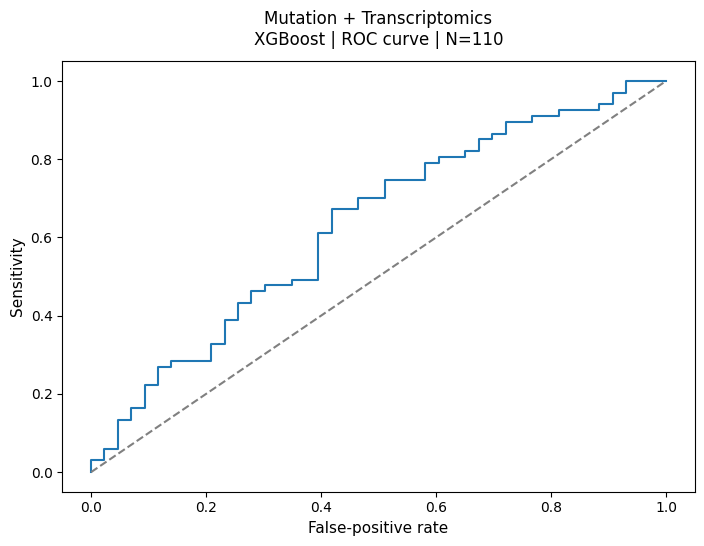

In [33]:
fig = plot_thesis_saved_figure('roc', 'mutation_transcriptomics')
plt.show()


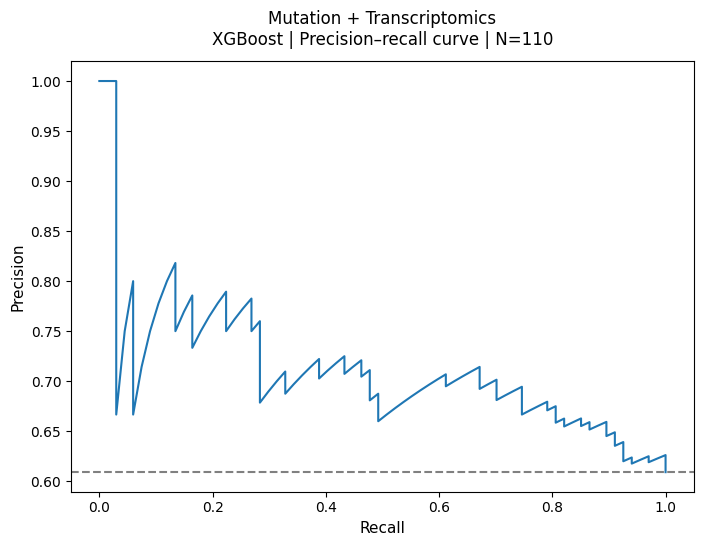

In [34]:
fig = plot_thesis_saved_figure('pr', 'mutation_transcriptomics')
plt.show()


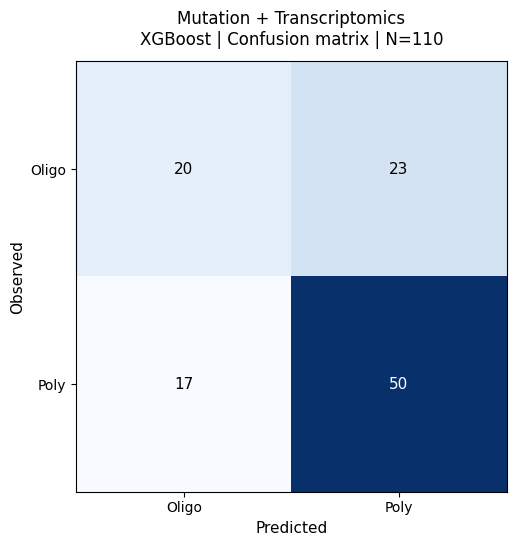

In [35]:
fig = plot_thesis_saved_figure('confusion_matrix', 'mutation_transcriptomics')
plt.show()


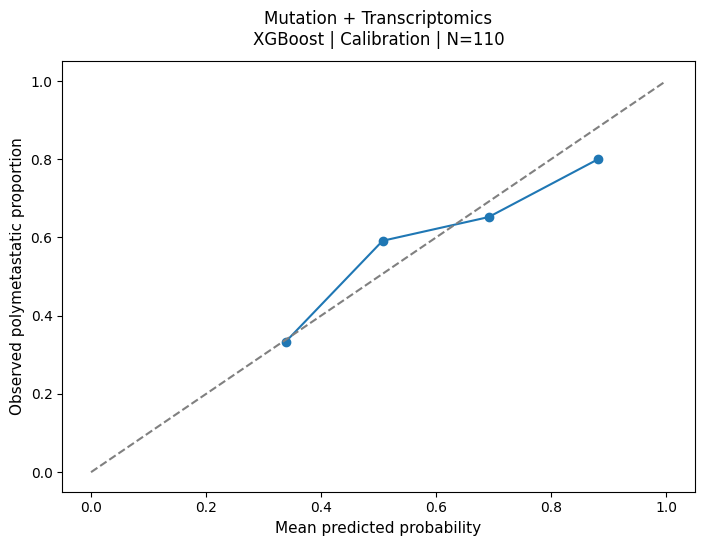

In [36]:
fig = plot_thesis_saved_figure('calibration', 'mutation_transcriptomics')
plt.show()


## Apparent training and held-out performance

Each distribution contains five saved outer-fold AUC values. Black dots denote individual folds. Outer-training performance is resubstitution performance on the fitted data, not inner validation. Its separation from held-out performance is an overfitting diagnostic. No separate gap series is plotted.

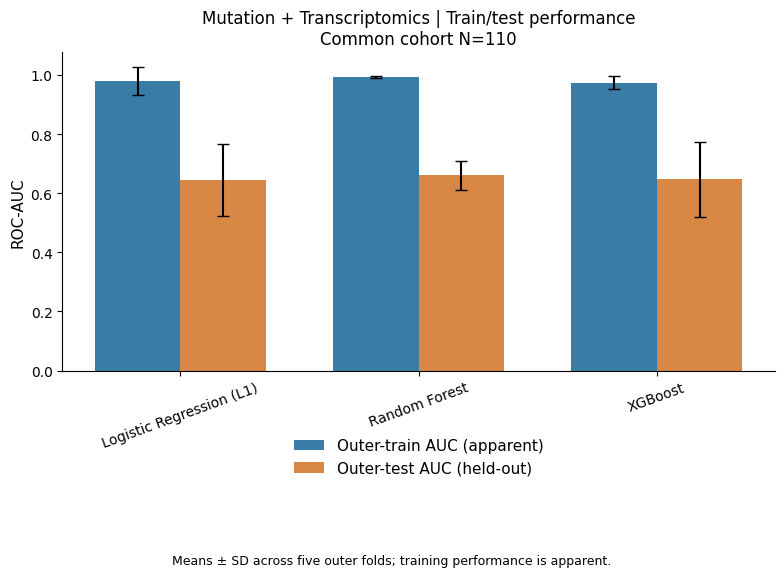

In [37]:
fig = plot_thesis_saved_figure('train_test', 'mutation_transcriptomics')
plt.show()


In [ ]:
display(pd.read_csv('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/primary_110/mutation_transcriptomics/mutation_transcriptomics_primary_110_train_test.csv')[['family', 'roc_auc_train_mean', 'roc_auc_train_std', 'roc_auc_test_mean', 'roc_auc_test_std']].style.format(precision=3))

family,roc_auc_train_mean,roc_auc_train_std,roc_auc_test_mean,roc_auc_test_std
logreg_l1,0.979,0.047,0.645,0.123
random_forest,0.994,0.004,0.661,0.050
xgboost,0.975,0.023,0.647,0.127


## Fold-specific feature selection

Retained inputs precede supervised selection; selected inputs are those entering the classifier. Recurrence below counts membership in the selected set across outer folds, not importance or biological stability. Modality counts describe feature composition and must not be interpreted as modality contributions.

In [ ]:
display(pd.read_csv('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/primary_110/mutation_transcriptomics/mutation_transcriptomics_primary_110_folds.csv').style.format(precision=3))

family,outer_fold,selector,retained_before_selection,selected_after_selection
xgboost,1,mi200,22327,200
xgboost,2,f200,22808,200
xgboost,3,mi200,22302,200
xgboost,4,f200,22067,200
xgboost,5,mi200,22324,200


In [ ]:
display(pd.read_csv('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/primary_110/mutation_transcriptomics/mutation_transcriptomics_primary_110_modality_counts.csv').pivot(index='outer_fold', columns='modality', values='n_classifier_inputs').fillna(0).astype(int))

modality,outer_fold,mutation,transcriptomics
,1,61,139
,2,58,142
,3,33,167
,4,53,147
,5,60,140


The complete feature-identity and recurrence tables are preserved alongside these figures in the reporting directory. They retain model-facing identifiers for traceability. This notebook does not treat selected-feature counts as native importance or SHAP.

## Interpretation scope

A separate full-cohort interpretation fit and SHAP analysis were not part of the approved five-model interpretation scope for these two pairwise inputs. TreeSHAP would be technically applicable to a saved fitted tree model, but no such pairwise interpretation model is available. No additional fit was added just to match the other notebooks.

### Most recurrent selected inputs

The first 20 entries are ordered by fold-selection frequency, with the preserved feature ordering used for ties. These are selection recurrence counts, not importance rankings.

In [ ]:
display_multimodal_interpretation(pd.read_csv('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/primary_110/mutation_transcriptomics/mutation_transcriptomics_primary_110_frequency.csv').head(20))

family,feature,modality,common_fold_selection_frequency,fraction_of_folds
xgboost,SLC6A15,mutation,3,0.600
xgboost,TAS2R16,mutation,3,0.600
xgboost,ZFHX2,mutation,3,0.600
xgboost,ALPK3,mutation,3,0.600
xgboost,RHBDD1,mutation,3,0.600
xgboost,PTPRG,mutation,3,0.600
xgboost,ANKZF1,mutation,3,0.600
xgboost,KIF4B,mutation,3,0.600
xgboost,MUC6,mutation,3,0.600
xgboost,MUC4,mutation,3,0.600
